In [ ]:
dog_eye = array([[280.90584416, 142.49675325],
       [321.44480519, 138.58766234],
       [190.87987013, 515.43181818],
       [234.06168831, 475.21753247]])

In [2]:
Ground_truth ={
       # two white dogs
       '000000204800':
              [[280.90584416, 142.49675325],
              [321.44480519, 138.58766234],
              [190.87987013, 515.43181818],
              [234.06168831, 475.21753247]],
       # one dog one cat
       '000000114269':
              [[263.72580645,  74.20322581],
              [330.47419355,  75.1       ],
              [430.93548387, 307.13225806],
              [465.05483871, 304.9516129 ]],
}

In [ ]:
import numpy as np
import cv2

def draw_mask_overlay(
    image,
    mask,
    color=(0, 230, 118),
    alpha=0.75,
    contour=True,
    contour_width=2
):
    # Convert to binary mask
    mask = np.asarray(mask).astype(bool)

    # Convert image to float RGB
    overlay = np.asarray(image).copy().astype(np.float32)

    # Apply solid color with transparency
    overlay[mask] = (
        (1 - alpha) * overlay[mask]
        + alpha * np.asarray(color)
    )

    # Draw visible mask contours
    if contour:
        binary_mask = mask.astype(np.uint8) * 255

        contours, _ = cv2.findContours(
            binary_mask,
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        # OpenCV uses BGR; convert RGB image to BGR
        overlay_bgr = cv2.cvtColor(
            overlay.astype(np.uint8),
            cv2.COLOR_RGB2BGR
        )

        cv2.drawContours(
            overlay_bgr,
            contours,
            -1,
            color=tuple(int(v) for v in color[::-1]),
            thickness=contour_width
        )

        overlay = cv2.cvtColor(
            overlay_bgr,
            cv2.COLOR_BGR2RGB
        )

    return np.clip(overlay, 0, 255).astype(np.uint8)

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def calculate_segmentation_metrics(gt_mask, pred_mask):
    # Convert masks to binary arrays
    gt = np.asarray(gt_mask).astype(bool)
    pred = np.asarray(pred_mask).astype(bool)

    # Ensure both masks use identical coordinates and dimensions
    if gt.shape != pred.shape:
        raise ValueError(
            f"Mask shape mismatch: GT={gt.shape}, Prediction={pred.shape}"
        )

    # Calculate pixel-level confusion statistics
    tp = np.logical_and(gt, pred).sum()
    fp = np.logical_and(~gt, pred).sum()
    fn = np.logical_and(gt, ~pred).sum()

    # Calculate segmentation metrics
    iou = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else np.nan
    dice = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else np.nan
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

    return {
        "IoU": float(iou),
        "Dice": float(dice),
        "Precision": float(precision),
        "Recall": float(recall),
    }


def compare_gt_vs_prediction(
    outputs,
    dog_idx,
    cat_idx,
    image_id="000000114269",
    annotation_dir="annotations",
    plot=True
):
    # ============================================================
    # STEP 1: Load manually annotated Ground Truth masks
    # ============================================================
    animal_gt_path = os.path.join(
        annotation_dir, f"{image_id}_animal_gt.npz"
    )
    eye_gt_path = os.path.join(
        annotation_dir, f"{image_id}_eye_gt.npz"
    )

    with np.load(animal_gt_path) as data:
        gt_animal_masks = {key: data[key] for key in data.files}

    with np.load(eye_gt_path) as data:
        gt_eye_masks = {key: data[key] for key in data.files}

    # ============================================================
    # STEP 2: Prepare animal indices and predictions
    # ============================================================
    animal_indices = {
        "dog": dog_idx,
        "cat": cat_idx
    }

    rows = []
    visualization_data = []

    # ============================================================
    # STEP 3: Compare Animal Instance Masks (YOLO)
    # ============================================================
    for animal_name, animal_idx in animal_indices.items():

        animal = outputs["animal_crops"][animal_idx]

        # Retrieve manually annotated animal mask
        gt_mask = gt_animal_masks[animal_name]

        # Retrieve YOLO prediction in crop coordinates
        pred_mask = animal["mask"]

        # Calculate pixel-level segmentation metrics
        metrics = calculate_segmentation_metrics(gt_mask, pred_mask)

        rows.append({
            "Model": "YOLO26-Seg",
            "Animal": animal_name.title(),
            "Region": "Animal",
            **metrics
        })

        visualization_data.append((
            f"{animal_name.title()} Animal",
            animal["original_crop"],
            gt_mask,
            pred_mask
        ))

    # ============================================================
    # STEP 4: Compare Eye Segmentation Masks (SAM 2.1)
    # ============================================================
    for animal_name, animal_idx in animal_indices.items():

        animal = outputs["animal_crops"][animal_idx]
        global_masks = outputs["global_eye_masks"][animal_idx]

        # Get crop position in the original image
        x_offset, y_offset = animal["offset"]
        h, w = animal["original_crop"].shape[:2]

        for eye_name in ["right_eye", "left_eye"]:

            key = f"{animal_name}_{eye_name}"
            gt_mask = gt_eye_masks[key]

            # Handle missing eye predictions explicitly
            if global_masks is None:
                pred_mask = np.zeros_like(gt_mask, dtype=np.uint8)
            else:
                # Crop global SAM mask back to animal ROI coordinates
                full_mask = global_masks[eye_name]

                pred_mask = full_mask[
                    y_offset:y_offset + h,
                    x_offset:x_offset + w
                ]

            # Calculate segmentation metrics
            metrics = calculate_segmentation_metrics(gt_mask, pred_mask)

            rows.append({
                "Model": "SAM 2.1",
                "Animal": animal_name.title(),
                "Region": eye_name.replace("_", " ").title(),
                **metrics
            })

            visualization_data.append((
                f"{animal_name.title()} {eye_name.replace('_', ' ').title()}",
                animal["original_crop"],
                gt_mask,
                pred_mask
            ))

    # ============================================================
    # STEP 5: Create and display evaluation table
    # ============================================================
    df = pd.DataFrame(rows)

    print("\n=== Segmentation Evaluation ===")
    display(df.round(4))

    print("\n=== Mean Metrics by Model ===")
    summary = (
        df.groupby("Model")[["IoU", "Dice", "Precision", "Recall"]]
        .mean()
        .round(4)
    )
    display(summary)
        
    # ============================================================
    # STEP 6: Improved GT vs Prediction Visualization
    # ============================================================
    if plot:
        from matplotlib.patches import Patch
        from matplotlib.lines import Line2D

        fig, axes = plt.subplots(
            len(visualization_data), 3,
            figsize=(15, 3.5 * len(visualization_data)),
            squeeze=False
        )

        for row_idx, (label, image, gt, pred) in enumerate(
            visualization_data
        ):
            gt = np.asarray(gt).astype(bool)
            pred = np.asarray(pred).astype(bool)

            # Calculate evaluation metrics
            metrics = calculate_segmentation_metrics(gt, pred)

            # Determine whether the current region is an eye
            is_eye = "Eye" in label

            # ----------------------------------------------------
            # Zoom into eye region for small masks
            # ----------------------------------------------------
            if is_eye:
                ys, xs = np.where(gt | pred)

                if len(xs) > 0:
                    x1, x2 = xs.min(), xs.max()
                    y1, y2 = ys.min(), ys.max()

                    # Padding around union of GT and prediction
                    size = max(x2 - x1, y2 - y1, 20)
                    pad = max(12, int(size * 1.2))

                    xlim = (
                        max(0, x1 - pad),
                        min(image.shape[1], x2 + pad)
                    )
                    ylim = (
                        min(image.shape[0], y2 + pad),
                        max(0, y1 - pad)
                    )
                else:
                    xlim = (0, image.shape[1])
                    ylim = (image.shape[0], 0)

            else:
                xlim = (0, image.shape[1])
                ylim = (image.shape[0], 0)

            # ----------------------------------------------------
            # Column 1: Ground Truth
            # ----------------------------------------------------
            ax = axes[row_idx, 0]

            gt_overlay = overlay_mask(
                image, gt,
                color=(0, 220, 90),
                alpha=0.45
            )

            ax.imshow(gt_overlay)
            draw_contour(ax, gt, color="lime", linewidth=2)

            ax.set_title(f"{label} - Ground Truth")

            # ----------------------------------------------------
            # Column 2: Prediction
            # ----------------------------------------------------
            ax = axes[row_idx, 1]

            pred_overlay = overlay_mask(
                image, pred,
                color=(255, 50, 50),
                alpha=0.45
            )

            ax.imshow(pred_overlay)
            draw_contour(ax, pred, color="red", linewidth=2)

            ax.set_title(f"{label} - Prediction")

            # ----------------------------------------------------
            # Column 3: Agreement / Error Map
            # ----------------------------------------------------
            ax = axes[row_idx, 2]

            fp = (~gt) & pred
            fn = gt & (~pred)

            # Only color incorrect regions
            error_map = image.copy()
            error_map = overlay_mask(
                error_map, fp,
                color=(255, 0, 0),
                alpha=0.85
            )
            error_map = overlay_mask(
                error_map, fn,
                color=(0, 100, 255),
                alpha=0.85
            )

            ax.imshow(error_map)

            # Show both boundaries
            draw_contour(ax, gt, color="lime", linewidth=1.8)
            draw_contour(ax, pred, color="magenta", linewidth=1.8)

            ax.set_title(
                f"{label} - IoU: {metrics['IoU']:.3f}, "
                f"Dice: {metrics['Dice']:.3f}"
            )

            # ----------------------------------------------------
            # Apply same view to all three columns
            # ----------------------------------------------------
            for ax in axes[row_idx]:
                ax.set_xlim(*xlim)
                ax.set_ylim(*ylim)
                ax.axis("off")

        # --------------------------------------------------------
        # Figure Legend
        # --------------------------------------------------------
        legend_elements = [
            Line2D([0], [0], color="lime", lw=2,
                label="GT Boundary"),
            Line2D([0], [0], color="magenta", lw=2,
                label="Prediction Boundary"),
            Patch(facecolor="red", label="FP - Over-segmentation"),
            Patch(facecolor="dodgerblue", label="FN - Under-segmentation")
        ]

        fig.legend(
            handles=legend_elements,
            loc="lower center",
            ncol=4,
            fontsize=11,
            frameon=False
        )

        plt.tight_layout(rect=[0, 0.05, 1, 1])
        plt.show()
        
    return {
        "metrics": df,
        "summary": summary
    }

SyntaxError: '[' was never closed (1345762900.py, line 259)


=== Segmentation Evaluation ===


,Model,Animal,Region,IoU,Dice,Precision,Recall
0,YOLO26-Seg,Dog,Animal,0.9650,0.9822,0.9759,0.9886
1,YOLO26-Seg,Cat,Animal,0.9419,0.9701,0.9768,0.9634
2,SAM 2.1,Dog,Right Eye,0.5979,0.7484,0.5979,1.0000
3,SAM 2.1,Dog,Left Eye,0.3153,0.4794,0.3153,1.0000
4,SAM 2.1,Cat,Right Eye,0.6667,0.8000,0.7387,0.8723
5,SAM 2.1,Cat,Left Eye,0.7267,0.8417,0.7415,0.9732



=== Mean Metrics by Model ===


,IoU,Dice,Precision,Recall
Model,,,,
SAM 2.1,0.5766,0.7174,0.5984,0.9614
YOLO26-Seg,0.9535,0.9761,0.9764,0.9760


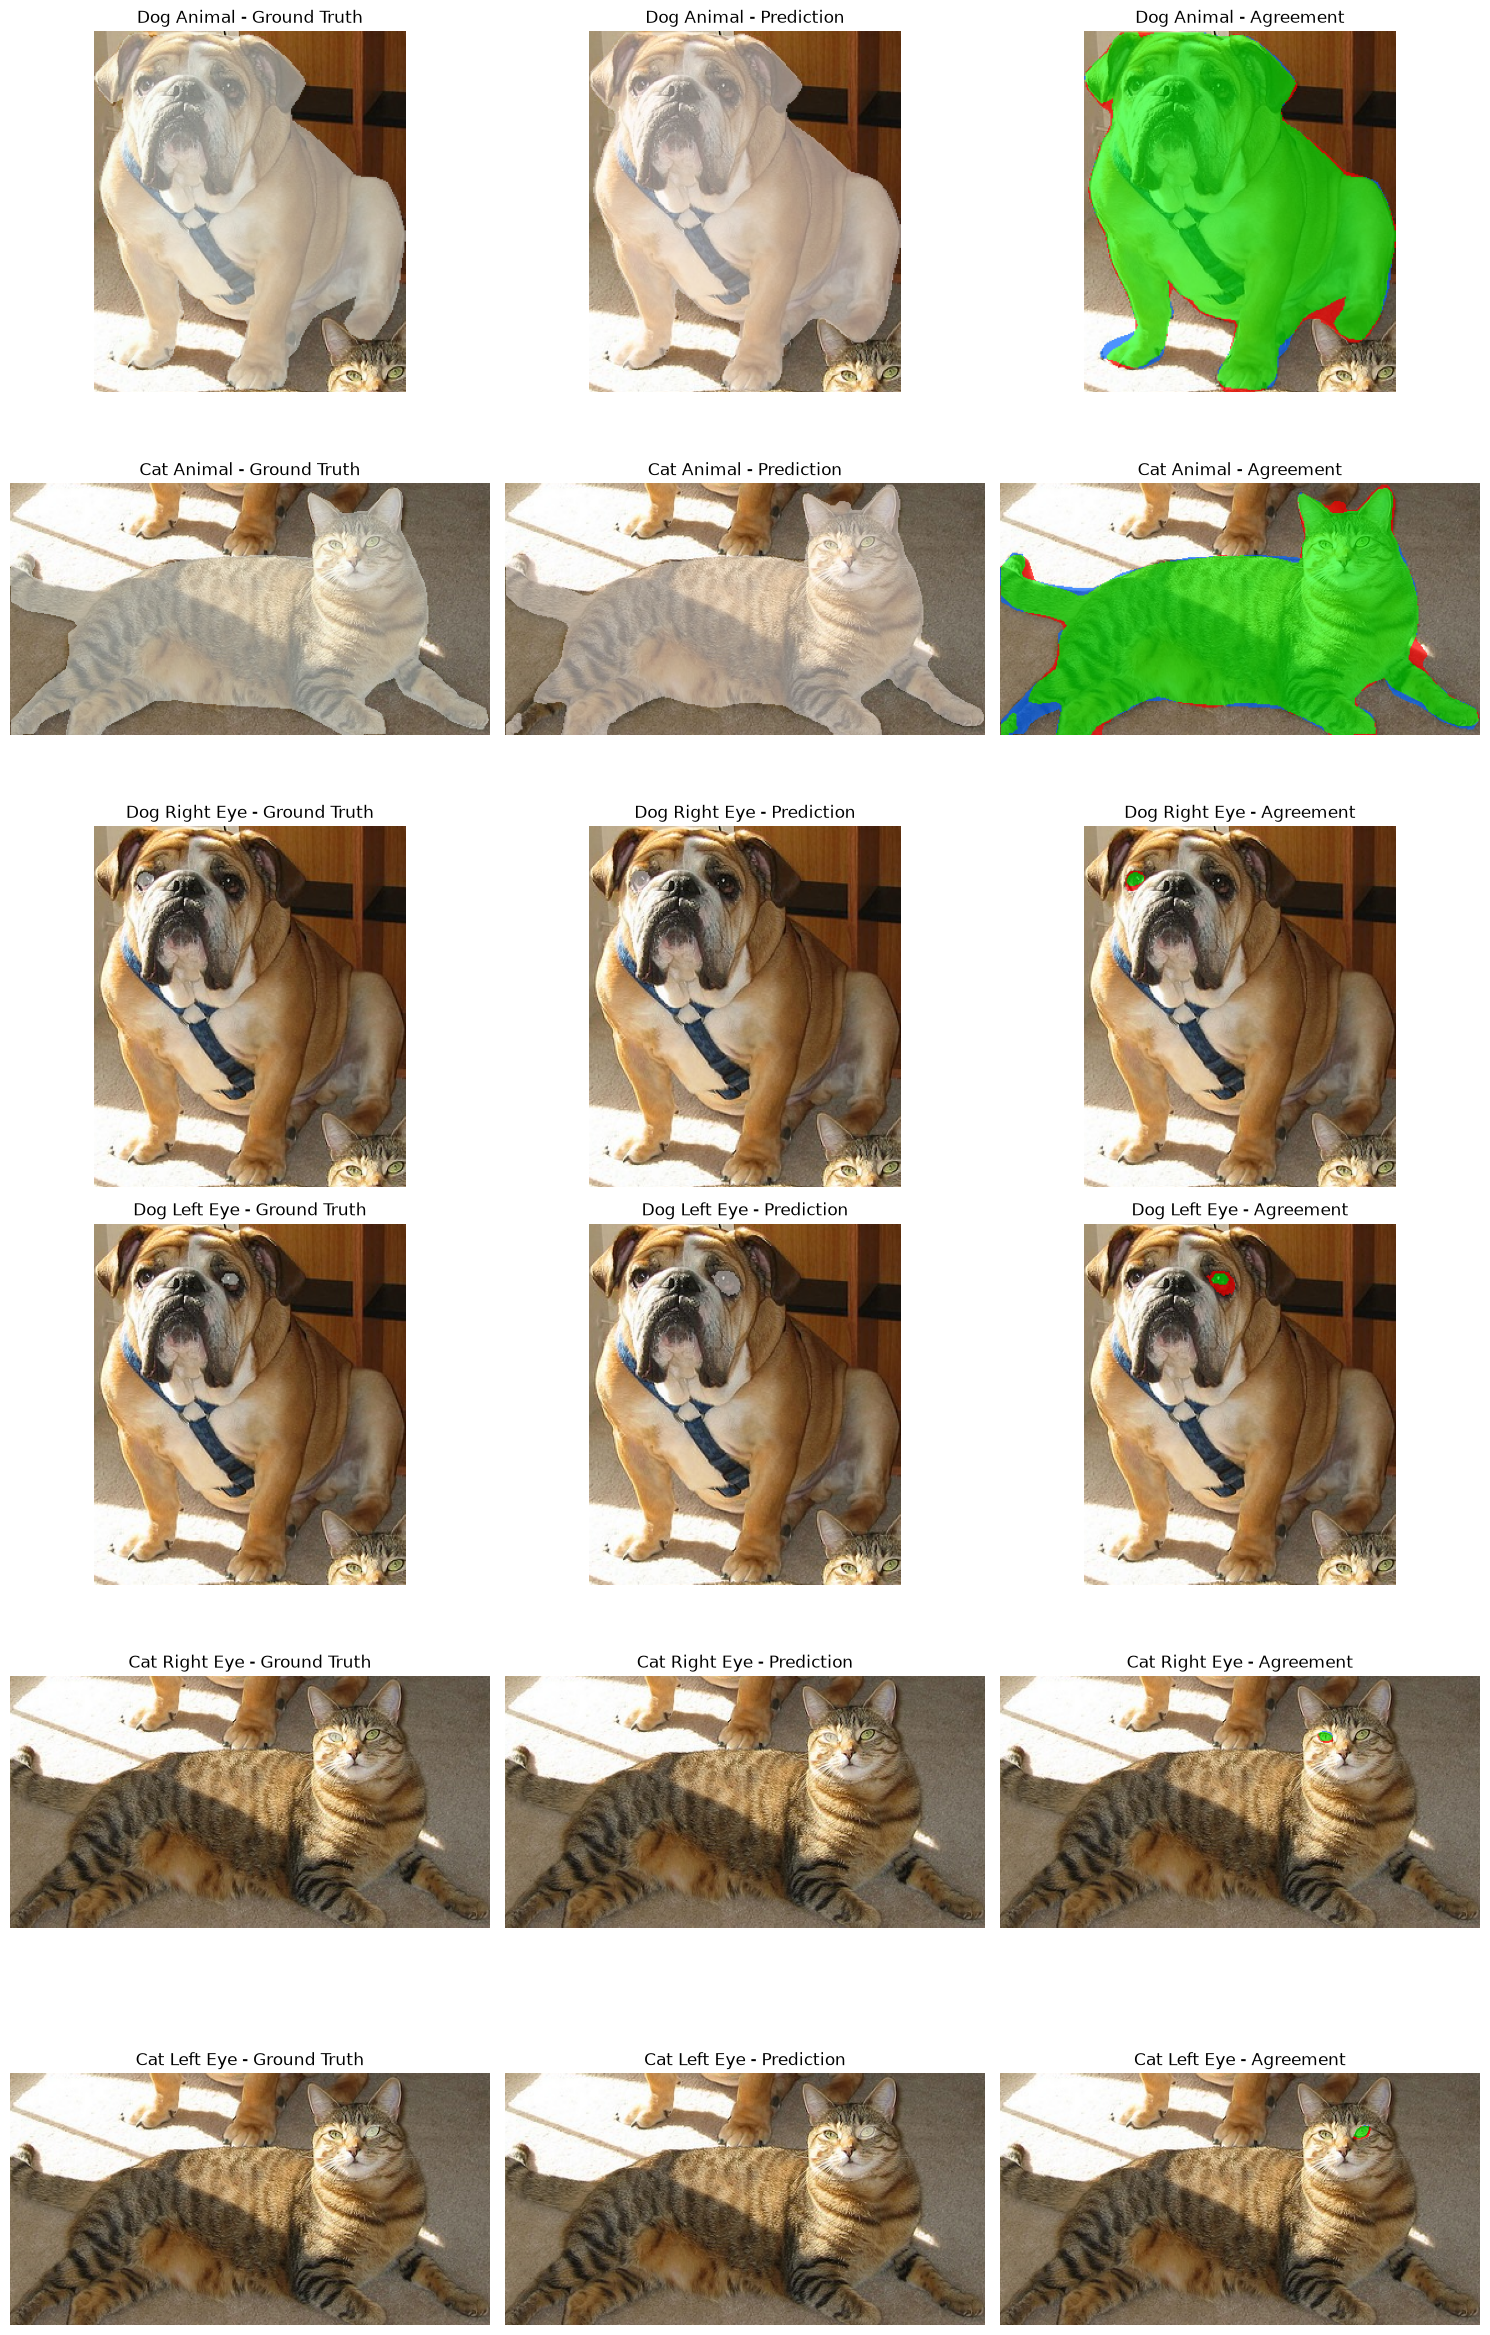

In [15]:
seg_evaluation = compare_gt_vs_prediction(
    outputs=outputs,
    dog_idx=0,
    cat_idx=1,
    image_id="000000114269",
    plot=True
)

In [3]:
# STEP 1: Animal Instance Segmentation
# Detect and segment individual animals using YOLO.
def step1_animal_mask_box(image_path,yolo_seg_path):
    # Load Yolo
    model = YOLO(yolo_seg_path)


    animal_classes = list(range(14, 24))

    # Yolo Inference
    results = model.predict(
        source=image_path,
        conf=0.2,
        iou=0.5,
        agnostic_nms=True,
        nms=True,
        classes=animal_classes,
        device="mps",
        verbose=False
    )

    result = results[0]

    return result

# STEP 1.5: Animal ROI Extraction
# Crop each animal and remove background interference.
def animial_ROI(image_path, result):
    image = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    H, W = image_rgb.shape[:2]
    animal_ROI_crops = []

    if result.masks is None:
        return animal_ROI_crops

    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    masks = result.masks.data.cpu().numpy()

    for i, (box, cls, mask) in enumerate(
        zip(boxes, classes, masks)
    ):
        x1, y1, x2, y2 = map(int, box)

        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(W, x2)
        y2 = min(H, y2)

        # Resize instance mask to original resolution
        if mask.shape != (H, W):
            mask = cv2.resize(
                mask.astype(np.float32),
                (W, H),
                interpolation=cv2.INTER_NEAREST
            )

        binary_mask = mask > 0.5

        # Crop image and corresponding instance mask
        crop = image_rgb[y1:y2, x1:x2].copy()
        crop_mask = binary_mask[y1:y2, x1:x2]

        # Replace background with neutral gray
        masked_crop = np.full_like(crop, 127)
        masked_crop[crop_mask] = crop[crop_mask]

        animal_ROI_crops.append({
            "image": masked_crop,
            "original_crop": crop,
            "mask": crop_mask,
            "offset": (x1, y1),
            "class_id": int(cls)
        })

    return animal_ROI_crops


# STEP 2: Eye Detection
# Use Grounding DINO to detect eye bounding boxes.
def step2_animal_eye_box(animal_ROI_crops):
    device = "mps" if torch.backends.mps.is_available() else "cpu"

    processor = AutoProcessor.from_pretrained(
        "IDEA-Research/grounding-dino-tiny"
    )

    dino = AutoModelForZeroShotObjectDetection.from_pretrained(
        "IDEA-Research/grounding-dino-tiny"
    ).to(device)

    dino.eval()

    all_eye_detections = []
    for ani_idx, animal in enumerate(animal_ROI_crops):
        pil_image = Image.fromarray(animal["image"])

        inputs = processor(
            images=pil_image,
            text="Animal two eye.",
            return_tensors="pt"
        ).to(device)

        with torch.no_grad():
            outputs = dino(**inputs)

        detections = processor.post_process_grounded_object_detection(
            outputs,
            inputs.input_ids,
            threshold=0.20,
            text_threshold=0.30,
            target_sizes=[pil_image.size[::-1]]
        )[0]
        all_eye_detections.append(detections)


        print(
            f"Animal {ani_idx+1}: "
            f"{len(detections['boxes'])} eye boxes detected"
        )

    return all_eye_detections


# STEP 2.5: Geometry-based Filtering
# Remove oversized eye candidates using geometric constraints.
def filter_eye_boxes(boxes, scores, image_shape,
                     max_area_ratio=0.10,
                     max_width_ratio=0.40,
                     max_height_ratio=0.35):

    h, w = image_shape[:2]

    valid_boxes = []
    valid_scores = []

    for box, score in zip(boxes, scores):
        x1, y1, x2, y2 = box

        bw = x2 - x1
        bh = y2 - y1

        area_ratio = (bw * bh) / (w * h)
        width_ratio = bw / w
        height_ratio = bh / h

        # Filter large boxes
        if area_ratio > max_area_ratio:
            continue

        if width_ratio > max_width_ratio:
            continue

        if height_ratio > max_height_ratio:
            continue

        valid_boxes.append(box)
        valid_scores.append(score)

    return (
        np.asarray(valid_boxes, dtype=np.float32).reshape(-1, 4),
        np.asarray(valid_scores, dtype=np.float32)
    )


def filter_all_animal_eye_boxes(all_eye_detections, animal_ROI_crops):

    filtered_detections = []

    for ani_idx, animal in enumerate(animal_ROI_crops):

        detections = all_eye_detections[ani_idx]

        boxes = detections["boxes"].cpu().numpy()
        scores = detections["scores"].cpu().numpy()

        # Geometry filter
        valid_boxes, valid_scores = filter_eye_boxes(
            boxes=boxes,
            scores=scores,
            image_shape=animal["image"].shape,
            max_area_ratio=0.10,
            max_width_ratio=0.40,
            max_height_ratio=0.35
        )

        # Convert back to torch.Tensor
        filtered = detections.copy()

        filtered["boxes"] = torch.as_tensor(
            valid_boxes,
            dtype=detections["boxes"].dtype,
            device=detections["boxes"].device
        )

        filtered["scores"] = torch.as_tensor(
            valid_scores,
            dtype=detections["scores"].dtype,
            device=detections["scores"].device
        )

        # Keep labels aligned with filtered boxes
        # （如果有使用 labels，建議原 filter 直接回傳保留的 indices）
        filtered.pop("labels", None)
        filtered.pop("text_labels", None)

        filtered_detections.append(filtered)

        print(
            f"Animal {ani_idx+1}: "
            f"{len(boxes)} → {len(valid_boxes)} eye candidates"
        )

    return filtered_detections

# STEP 3: Eye Segmentation
# Use SAM 2 to generate binary eye masks.
def step3_animal_eye_mask(detections, animal_ROI_crops):
    sam = SAM("models/sam2.1_t.pt")

    all_eye_masks = []

    for ani_idx, animal in enumerate(animal_ROI_crops):

        img = animal["original_crop"]

        boxes = detections[ani_idx]["boxes"].cpu().numpy()
        scores = detections[ani_idx]["scores"].cpu().numpy()

        # Select top 2 eye boxes
        top2 = np.argsort(scores)[::-1][:2]
        eye_boxes = boxes[top2]

        if len(eye_boxes) != 2:
            print(f"Animal {ani_idx+1}: Expected 2 eye boxes")
            all_eye_masks.append([])
            continue

        results_sam = sam.predict(
            source=img,
            bboxes=eye_boxes.tolist(),
            verbose=False
        )

        if results_sam[0].masks is None:
            all_eye_masks.append([])
            continue

        eye_masks = results_sam[0].masks.data.cpu().numpy()

        all_eye_masks.append(eye_masks)

    return all_eye_masks


# STEP 4: Eye Landmark Extraction
# Calculate mask centroids and restore original image coordinates.
def eye_mask_centroid(all_eye_masks, animal_ROI_crops, image_path):

    image = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    H, W = image_rgb.shape[:2]

    # 儲存所有動物的眼睛資料
    all_eye_landmarks = []
    all_eye_global_masks = []

    for ani_idx, animal in enumerate(animal_ROI_crops):

        crop = animal["image"]
        x_offset, y_offset = animal["offset"]

        crop_h, crop_w = crop.shape[:2]

        masks = all_eye_masks[ani_idx]

        if len(masks) != 2:
            print(f"animal {ani_idx+1}: Expected 2 eye masks")
            all_eye_landmarks.append(None)
            all_eye_global_masks.append(None)
            continue

        eye_data = []

        for mask in masks:

            # Resize mask to crop resolution if necessary
            if mask.shape != (crop_h, crop_w):
                mask = cv2.resize(
                    mask.astype(np.float32),
                    (crop_w, crop_h),
                    interpolation=cv2.INTER_NEAREST
                )

            mask = mask > 0.5

            # Calculate local centroid
            ys, xs = np.where(mask)

            if len(xs) == 0:
                continue

            cx_local = xs.mean()
            cy_local = ys.mean()

            # Convert to original image coordinates
            cx_global = cx_local + x_offset
            cy_global = cy_local + y_offset

            # Restore mask to original image
            global_mask = np.zeros((H, W), dtype=np.uint8)

            global_mask[
                y_offset:y_offset+crop_h,
                x_offset:x_offset+crop_w
            ] = mask.astype(np.uint8)

            eye_data.append({
                "centroid": (cx_global, cy_global),
                "mask": global_mask
            })

        if len(eye_data) != 2:
            all_eye_landmarks.append(None)
            all_eye_global_masks.append(None)
            continue

        # Sort by X coordinate (front-facing dog)
        eye_data.sort(key=lambda e: e["centroid"][0])

        # Anatomical orientation
        right_eye = eye_data[0]
        left_eye = eye_data[1]

        all_eye_landmarks.append({
            "right_eye": right_eye["centroid"],
            "left_eye": left_eye["centroid"]
        })

        all_eye_global_masks.append({
            "right_eye": right_eye["mask"],
            "left_eye": left_eye["mask"]
        })

        print(f"Animal {ani_idx+1}")
        print(" Right eye:", right_eye["centroid"])
        print(" Left eye:", left_eye["centroid"])

    return all_eye_landmarks, all_eye_global_masks


def distance_between_points(p1, p2):
    return float(np.linalg.norm(np.array(p1) - np.array(p2)))

# STEP 5: Geometric Measurement
# Calculate inter-eye and between-animal right-eye distances.
def get_eye_distance(all_eye_landmarks):

    # SAM 2 predicted eye centroids
    
    valid_animals = {
        i + 1: landmarks
        for i, landmarks in enumerate(all_eye_landmarks)
        if landmarks is not None
    }

    results = {
        "inter_eye_distances": {},
        "between_right_eyes": {}
    }

    # 每隻成功偵測的動物：左右眼距離
    for animal_id, landmarks in valid_animals.items():

        distance = distance_between_points(
            landmarks["right_eye"],
            landmarks["left_eye"]
        )

        results["inter_eye_distances"][animal_id] = distance

    # 任意兩隻動物：右眼距離
    from itertools import combinations

    for (id1, animal1), (id2, animal2) in combinations(
        valid_animals.items(), 2
    ):
        distance = distance_between_points(
            animal1["right_eye"],
            animal2["right_eye"]
        )

        results["between_right_eyes"][
            f"Animal {id1} - Animal {id2}"
        ] = distance

    return results


# STEP 6: Visualization
# Display detection, segmentation, landmarks, and measurements.
def plot_all(image_path, result, animal_ROI_crops, animal_eye_box, animal_eye_masks, all_eye_landmarks, all_eye_global_masks):


    image = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # ==============================================
    # 1. Original Image
    # ==============================================
    plt.figure(figsize=(9, 10))
    plt.imshow(image_rgb)
    plt.title("1. Original COCO Image")
    plt.axis("off")
    plt.show()

    # ==============================================
    # 2. YOLO Animal Instance Segmentation
    # ==============================================
    annotated = result.plot(
        boxes=True,
        masks=True,
        labels=True
    )

    plt.figure(figsize=(9, 10))
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.title("2. YOLO Animal Instance Segmentation")
    plt.axis("off")
    plt.show()

    # ==============================================
    # 3. Grounding DINO Eye Detection
    # ==============================================
    n_animals = len(animal_ROI_crops)

    fig, axes = plt.subplots(
        1, n_animals,
        figsize=(6 * n_animals, 7),
        squeeze=False
    )

    for ani_idx, animal in enumerate(animal_ROI_crops):

        ax = axes[0, ani_idx]
        img = animal["image"]

        detections = animal_eye_box[ani_idx]

        boxes = detections["boxes"].cpu().numpy()
        scores = detections["scores"].cpu().numpy()

        # Select top 2
        top2 = np.argsort(scores)[::-1][:2]

        ax.imshow(img)

        for box, score in zip(boxes[top2], scores[top2]):

            x1, y1, x2, y2 = box

            rect = patches.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )

            ax.add_patch(rect)

            ax.text(
                x1, y1 - 5,
                f"Eye {score:.2f}",
                color="yellow",
                fontsize=10,
                weight="bold"
            )

        ax.set_title(
            f"3. Animal {ani_idx+1} - Eye Detection"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    # ==============================================
    # 4. SAM 2 Eye Segmentation
    # ==============================================
    fig, axes = plt.subplots(
        1, n_animals,
        figsize=(6 * n_animals, 7),
        squeeze=False
    )

    for ani_idx, animal in enumerate(animal_ROI_crops):

        ax = axes[0, ani_idx]
        img = animal["image"]
        masks = animal_eye_masks[ani_idx]

        ax.imshow(img)

        for mask in masks:

            # Match mask resolution with crop
            h, w = img.shape[:2]

            if mask.shape != (h, w):
                mask = cv2.resize(
                    mask.astype(np.float32),
                    (w, h),
                    interpolation=cv2.INTER_NEAREST
                )

            ax.imshow(
                np.ma.masked_where(mask <= 0.5, mask),
                cmap="spring",
                alpha=0.5
            )

        ax.set_title(
            f"4. Animal {ani_idx+1} - SAM 2 Eye Masks"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    # ==============================================
    # 5. Eye Centroids + Distance Measurement
    # ==============================================
    fig, ax = plt.subplots(figsize=(10, 12))

    ax.imshow(image_rgb)

    colors = {
        "right_eye": "lime",
        "left_eye": "cyan"
    }

    # Plot Global Eye Masks and Centroids
    for ani_idx, (landmarks, masks) in enumerate(
        zip(all_eye_landmarks, all_eye_global_masks)
    ):

        if landmarks is None or masks is None:
            continue

        for eye_name in ["right_eye", "left_eye"]:

            mask = masks[eye_name]
            cx, cy = landmarks[eye_name]

            # Mask overlay
            ax.imshow(
                np.ma.masked_where(mask == 0, mask),
                cmap="spring",
                alpha=0.45
            )

            # Centroid
            ax.scatter(
                cx, cy,
                color=colors[eye_name],
                edgecolors="black",
                s=65,
                zorder=5
            )

            ax.text(
                cx + 5,
                cy - 8,
                f"A{ani_idx+1} {eye_name}",
                color=colors[eye_name],
                fontsize=9,
                weight="bold"
            )

    # ----------------------------------------------
    # Distance lines
    # ----------------------------------------------
    valid_animals = [
        (i, lm)
        for i, lm in enumerate(all_eye_landmarks)
        if lm is not None
    ]

    measurement_pairs = []

    # Each animal's inter-eye distance
    for ani_idx, landmarks in valid_animals:

        measurement_pairs.append((
            landmarks["right_eye"],
            landmarks["left_eye"],
            f"Animal {ani_idx+1}",
            "yellow"
        ))

    # Between first two valid animals' right eyes
    if len(valid_animals) >= 2:

        idx1, ani1 = valid_animals[0]
        idx2, ani2 = valid_animals[1]

        measurement_pairs.append((
            ani1["right_eye"],
            ani2["right_eye"],
            f"A{idx1+1}-A{idx2+1} Right Eyes",
            "red"
        ))

    for p1, p2, label, color in measurement_pairs:

        d = distance_between_points(p1, p2)

        ax.plot(
            [p1[0], p2[0]],
            [p1[1], p2[1]],
            color=color,
            linewidth=2,
            linestyle="--" if color == "red" else "-"
        )

        mid = (np.array(p1) + np.array(p2)) / 2

        ax.text(
            mid[0] + 5,
            mid[1] - 10,
            f"{label}: {d:.2f} px",
            color=color,
            fontsize=10,
            weight="bold",
            bbox=dict(
                facecolor="black",
                alpha=0.5,
                edgecolor="none"
            )
        )

    ax.set_title(
        "5. Eye Segmentation, Centroids & Metrology"
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()



def get_animal_eye_point_distance_solution1(
                            image_path = "images/000000204800.jpg",
                            yolo_seg_path = "models/yolo26n-seg.pt",
                            plot = False
                            ):

    result = step1_animal_mask_box(image_path, yolo_seg_path)

    animal_ROI_crops = animial_ROI(image_path, result)

    animal_eye_box = step2_animal_eye_box(animal_ROI_crops)

    animal_eye_box = filter_all_animal_eye_boxes(
                        animal_eye_box,
                        animal_ROI_crops
                    )

    animal_eye_masks = step3_animal_eye_mask(animal_eye_box,animal_ROI_crops)

    all_eye_landmarks, all_eye_global_masks = eye_mask_centroid(animal_eye_masks, animal_ROI_crops, image_path)

    results = get_eye_distance(all_eye_landmarks)


    if plot:
        plot_all(image_path, result,animal_ROI_crops, animal_eye_box, animal_eye_masks, all_eye_landmarks, all_eye_global_masks)

    return {
        "animal_result": result,
        "animal_crops": animal_ROI_crops,
        "eye_detections": animal_eye_box,
        "eye_masks": animal_eye_masks,
        "eye_landmarks": all_eye_landmarks,
        "global_eye_masks": all_eye_global_masks,
        "distances": results
    }


In [4]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def plot_animal_demo(animal_idx, animal_name,
                     animal_ROI_crops, all_eye_masks):

    animal = animal_ROI_crops[animal_idx]

    # Original RGB crop
    img = animal["original_crop"]

    # YOLO instance mask in crop coordinates
    animal_mask = animal["mask"].astype(bool)

    # SAM 2 eye masks
    eye_masks = all_eye_masks[animal_idx]

    h, w = img.shape[:2]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # 1. Original Animal Crop
    axes[0].imshow(img)
    axes[0].set_title(f"{animal_name} - Original")

    # 2. Animal Instance Mask
    axes[1].imshow(img)
    axes[1].imshow(
        np.ma.masked_where(~animal_mask, animal_mask),
        cmap="spring",
        alpha=0.5
    )
    axes[1].set_title(f"{animal_name} - Animal Mask")

    # 3. SAM 2 Eye Masks
    axes[2].imshow(img)

    if len(eye_masks) == 2:

        for mask in eye_masks:

            if mask.shape != (h, w):
                mask = cv2.resize(
                    mask.astype(np.float32),
                    (w, h),
                    interpolation=cv2.INTER_NEAREST
                )

            binary = mask > 0.5

            axes[2].imshow(
                np.ma.masked_where(~binary, binary),
                cmap="spring",
                alpha=0.55
            )

            # Eye Mask Centroid
            ys, xs = np.where(binary)

            if len(xs) > 0:
                axes[2].scatter(
                    xs.mean(),
                    ys.mean(),
                    c="lime",
                    edgecolors="black",
                    s=50,
                    zorder=5
                )

    else:
        axes[2].text(
            0.5, 0.5,
            "Eye masks unavailable",
            transform=axes[2].transAxes,
            ha="center",
            va="center",
            color="red"
        )

    axes[2].set_title(f"{animal_name} - Eye Masks")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [5]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import torch
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from PIL import Image
import matplotlib.patches as patches
from ultralytics import SAM
import numpy as np

/Users/yun/anaconda3/envs/animal-metrology/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1031 17:35:54.720000 71475 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [6]:
outputs = get_animal_eye_point_distance_solution1(
    image_path="images/000000114269.jpg",
    plot=False
)

Loading weights: 100%|██████████| 978/978 [00:00<00:00, 7354.27it/s]


Animal 1: 7 eye boxes detected
Animal 2: 6 eye boxes detected
Animal 1: 7 → 6 eye candidates
Animal 2: 6 → 5 eye candidates
Animal 1
 Right eye: (np.float64(261.79896907216494), np.float64(73.03092783505156))
 Left eye: (np.float64(332.20063694267515), np.float64(76.69426751592357))
Animal 2
 Right eye: (np.float64(429.5765765765766), np.float64(306.48648648648646))
 Left eye: (np.float64(463.2312925170068), np.float64(304.57142857142856))


In [7]:

# Animal 1
#  Right eye: (np.float64(261.79896907216494), np.float64(73.03092783505156))
#  Left eye: (np.float64(332.20063694267515), np.float64(76.69426751592357))
# Animal 2
#  Right eye: (np.float64(429.5765765765766), np.float64(306.48648648648646))
#  Left eye: (np.float64(463.2312925170068), np.float64(304.57142857142856))
Ground_truth ={
       # two white dogs
       '000000204800':
              [[280.90584416, 142.49675325],
              [321.44480519, 138.58766234],
              [190.87987013, 515.43181818],
              [234.06168831, 475.21753247]],
       # one dog one cat
       '000000114269':
              [[263.72580645,  74.20322581],
              [330.47419355,  75.1       ],
              [430.93548387, 307.13225806],
              [465.05483871, 304.9516129 ]],
}



In [8]:
import numpy as np
import pandas as pd
from itertools import combinations
from IPython.display import display


def evaluate_eye_metrology(
    all_eye_landmarks,
    ground_truth,
    image_id="000000114269",
    animal_names=("Dog", "Cat")
):
    # ============================================================
    # STEP 1: Load Ground Truth and Predictions
    # ============================================================
    gt = np.asarray(ground_truth[image_id], dtype=float)

    if gt.shape != (4, 2):
        raise ValueError("Expected GT shape (4, 2)")

    if len(all_eye_landmarks) != 2:
        raise ValueError("Expected exactly 2 predicted animals")

    labels = ["right_eye", "left_eye"]

    # Assumes predicted animals follow the same order as GT
    pred = np.array([
        all_eye_landmarks[i][eye]
        for i in range(2)
        for eye in labels
    ], dtype=float)

    # ============================================================
    # STEP 2: Evaluate Eye Landmark Localization
    # ============================================================
    landmark_rows = []

    for i in range(4):
        animal_idx = i // 2
        eye_name = labels[i % 2]

        error = np.linalg.norm(pred[i] - gt[i])

        # Normalize by the corresponding animal's GT inter-eye distance
        start = animal_idx * 2
        gt_inter_eye = np.linalg.norm(gt[start] - gt[start + 1])

        landmark_rows.append({
            "Animal": animal_names[animal_idx],
            "Eye": eye_name.replace("_", " ").title(),
            "GT X": gt[i, 0],
            "GT Y": gt[i, 1],
            "Pred X": pred[i, 0],
            "Pred Y": pred[i, 1],
            "Localization Error (px)": error,
            "NME (%)": error / gt_inter_eye * 100
        })

    landmark_df = pd.DataFrame(landmark_rows)

    # ============================================================
    # STEP 3: Evaluate Distance Measurement
    # ============================================================
    measurement_pairs = [
        (0, 1, f"{animal_names[0]} Inter-eye"),
        (2, 3, f"{animal_names[1]} Inter-eye"),
        (0, 2, "Between Animals Right-eye")
    ]

    distance_rows = []

    for i, j, measurement in measurement_pairs:
        gt_distance = np.linalg.norm(gt[i] - gt[j])
        pred_distance = np.linalg.norm(pred[i] - pred[j])
        difference = pred_distance - gt_distance

        distance_rows.append({
            "Measurement": measurement,
            "GT (px)": gt_distance,
            "Prediction (px)": pred_distance,
            "Difference (px)": difference,
            "Absolute Error (px)": abs(difference),
            "Error (%)": abs(difference) / gt_distance * 100
        })

    distance_df = pd.DataFrame(distance_rows)

    # ============================================================
    # STEP 4: Calculate Summary Metrics
    # ============================================================
    errors = distance_df["Difference (px)"].to_numpy()

    summary_df = pd.DataFrame([{
        "Localization MAE (px)": landmark_df["Localization Error (px)"].mean(),
        "NME (%)": landmark_df["NME (%)"].mean(),
        "Distance MAE (px)": np.mean(np.abs(errors)),
        "Distance RMSE (px)": np.sqrt(np.mean(errors ** 2)),
        "Distance MAPE (%)": distance_df["Error (%)"].mean()
    }])

    # ============================================================
    # STEP 5: Display Evaluation Tables
    # ============================================================
    print("=== Eye Landmark Localization ===")
    display(landmark_df.round(3))

    print("=== Distance Measurement ===")
    display(distance_df.round(3))

    print("=== Summary Metrics ===")
    display(summary_df.round(3))

    return {
        "landmarks": landmark_df,
        "distances": distance_df,
        "summary": summary_df
    }

In [9]:
evaluation = evaluate_eye_metrology(
    all_eye_landmarks=outputs["eye_landmarks"],
    ground_truth=Ground_truth,
    image_id="000000114269",
    animal_names=("Dog", "Cat")
)

=== Eye Landmark Localization ===


,Animal,Eye,GT X,GT Y,Pred X,Pred Y,Localization Error (px),NME (%)
0,Dog,Right Eye,263.726,74.203,261.799,73.031,2.255,3.379
1,Dog,Left Eye,330.474,75.100,332.201,76.694,2.350,3.520
2,Cat,Right Eye,430.935,307.132,429.577,306.486,1.505,4.401
3,Cat,Left Eye,465.055,304.952,463.231,304.571,1.863,5.448


=== Distance Measurement ===


,Measurement,GT (px),Prediction (px),Difference (px),Absolute Error (px),Error (%)
0,Dog Inter-eye,66.754,70.497,3.743,3.743,5.606
1,Cat Inter-eye,34.189,33.709,-0.480,0.480,1.403
2,Between Animals Right-eye,286.732,287.491,0.759,0.759,0.265


=== Summary Metrics ===


,Localization MAE (px),NME (%),Distance MAE (px),Distance RMSE (px),Distance MAPE (%)
0,1.993,4.187,1.66,2.222,2.425


In [16]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

def plot_eye_landmarks_gt(
    image_path,
    all_eye_landmarks,
    ground_truth,
    image_id="000000114269",
    animal_names=("Dog", "Cat")
):
    # ============================================================
    # STEP 1: Load Original Image and Ground Truth
    # ============================================================
    image = cv2.cvtColor(
        cv2.imread(image_path),
        cv2.COLOR_BGR2RGB
    )

    gt = np.asarray(ground_truth[image_id], dtype=float)

    if gt.shape != (4, 2):
        raise ValueError("Expected Ground Truth shape (4, 2)")

    # ============================================================
    # STEP 2: Create Figure
    # ============================================================
    fig, ax = plt.subplots(figsize=(12, 9))
    ax.imshow(image)

    eye_names = ["right_eye", "left_eye"]

    # ============================================================
    # STEP 3: Plot Ground Truth and Prediction Points
    # ============================================================
    for animal_idx, animal_name in enumerate(animal_names):

        landmarks = all_eye_landmarks[animal_idx]

        if landmarks is None:
            print(f"{animal_name}: Prediction unavailable")
            continue

        for eye_idx, eye_name in enumerate(eye_names):

            # Ground Truth point
            gt_point = gt[animal_idx * 2 + eye_idx]

            # Predicted centroid
            pred_point = np.asarray(
                landmarks[eye_name], dtype=float
            )

            # Calculate localization error
            error = np.linalg.norm(pred_point - gt_point)

            # Plot Ground Truth
            ax.scatter(
                gt_point[0], gt_point[1],
                color="lime",
                marker="o",
                s=90,
                edgecolors="black",
                linewidths=1.2,
                zorder=5,
                label="Ground Truth" if animal_idx == 0 and eye_idx == 0 else None
            )

            # Plot Prediction
            ax.scatter(
                pred_point[0], pred_point[1],
                color="red",
                marker="x",
                s=110,
                linewidths=2,
                zorder=6,
                label="Prediction" if animal_idx == 0 and eye_idx == 0 else None
            )

            # Draw localization error line
            ax.plot(
                [gt_point[0], pred_point[0]],
                [gt_point[1], pred_point[1]],
                color="yellow",
                linestyle="--",
                linewidth=1.5
            )

            # Display error value
            ax.annotate(
                f"{animal_name} {eye_name}\n{error:.2f} px",
                xy=gt_point,
                xytext=(8, -20 if eye_idx == 0 else 12),
                textcoords="offset points",
                color="yellow",
                fontsize=9,
                weight="bold",
                bbox=dict(
                    facecolor="black",
                    alpha=0.6,
                    edgecolor="none"
                )
            )

    # ============================================================
    # STEP 4: Display Results
    # ============================================================
    ax.legend(loc="upper right")
    ax.set_title("Eye Landmark Localization: Ground Truth vs Prediction")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

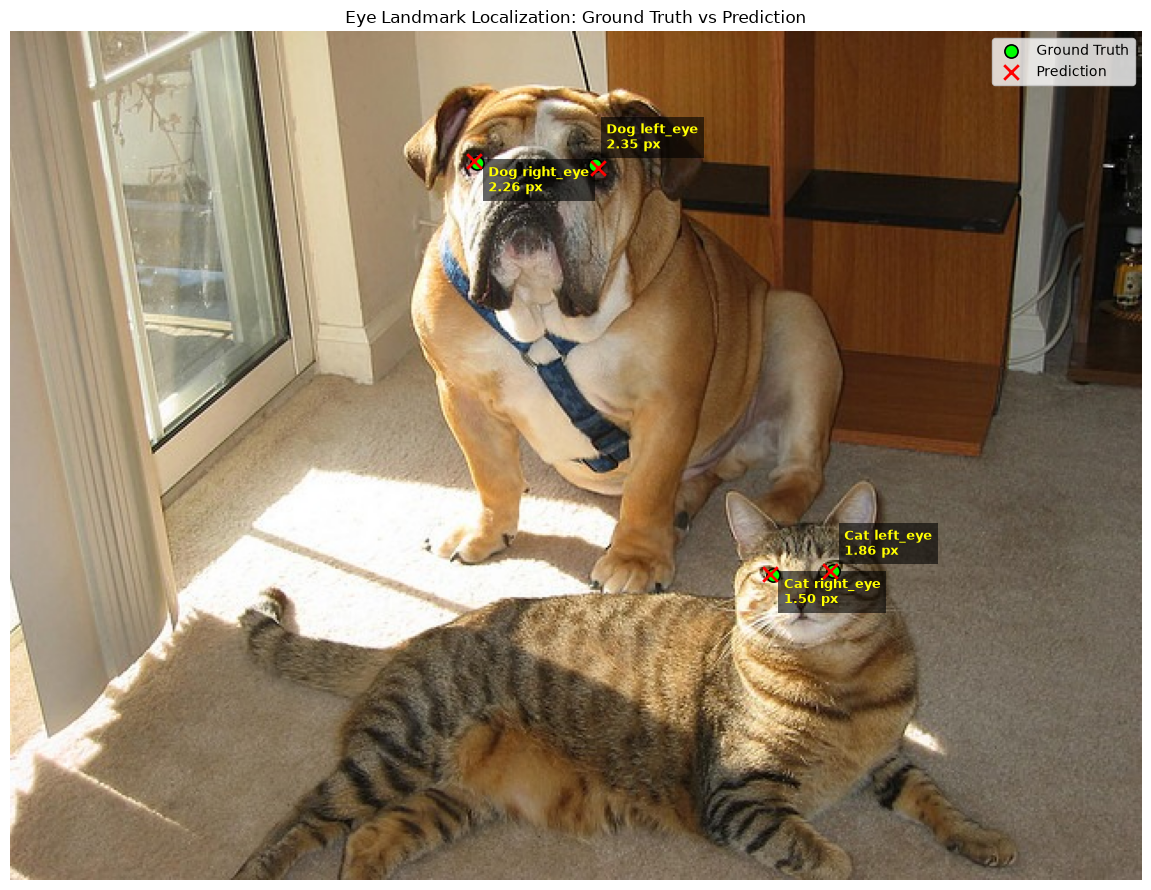

In [17]:
plot_eye_landmarks_gt(
    image_path="images/000000114269.jpg",
    all_eye_landmarks=outputs["eye_landmarks"],
    ground_truth=Ground_truth,
    image_id="000000114269",
    animal_names=("Dog", "Cat")
)